# Session 1 — Attention inside a real model

Session 0 ended with the model scoring every position of a text in a single pass. What lets position 30 use what was said at position 3 is attention. Basic Session 11 built it by hand on a small designed example. This session writes it out for GPT-2, checks that our version reproduces the real model to within rounding error, measures why the scores are divided by $\sqrt{d_k}$, and then looks for heads in GPT-2 that do an identifiable job.

**By the end of the session you should be able to:**

1. write scaled dot-product attention with its tensor shapes, and show that it reproduces a layer of a real model;
2. explain from a measurement why the scores are divided by $\sqrt{d_k}$;
3. recognise an induction head from its attention pattern, and test by ablation whether a head with a clear pattern is also one the model needs.

**To run it yourself** you need `numpy`, `pandas`, `matplotlib`, `scipy`, `torch` and `transformers`, and the GPT-2 download from Session 0. The outputs are already saved in the notebook. It takes under a minute on a GPU. The ablation cells run the model several hundred times on 101 tokens, which is quick on a laptop CPU too. Your numbers may differ in the last digit.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from scipy.stats import spearmanr
from aij_common import DEVICE, set_seed, load_gpt2
set_seed(0)
tok, model = load_gpt2(attn="eager")   # eager attention returns the attention weights
cfg = model.config
print(f"{cfg.n_layer} layers x {cfg.n_head} heads, d_model {cfg.n_embd}, head size {cfg.n_embd // cfg.n_head}")

12 layers x 12 heads, d_model 768, head size 64


The next cell holds helper functions: a softmax, a function that returns the bits needed for each token, and a function that runs GPT-2 with chosen attention heads switched off. Presenters skip it on screen. You can read it afterwards.

In [2]:
def softmax(x): e = np.exp(x - x.max(-1, keepdims=True)); return e / e.sum(-1, keepdims=True)

@torch.no_grad()
def run(ids, **kw):
    return model(torch.as_tensor(ids, device=DEVICE).view(1, -1), **kw)

def bits_per_position(ids, out=None):
    """Bits the model needs for each token of ids[1:], given the tokens before it."""
    ids = torch.as_tensor(ids, device=DEVICE).view(1, -1)
    logits = (out or run(ids)).logits[0].float()
    return (-logits[:-1].log_softmax(-1).gather(1, ids[0, 1:, None])[:, 0] / np.log(2)).cpu().numpy()

def ablate_heads(ids, heads):
    """Run the model with the given (layer, head) pairs zeroed, by blanking their slice of the input to the attention output projection."""
    hooks = []
    for layer in sorted({l for l, _ in heads}):
        cols = [h for l, h in heads if l == layer]
        def pre(module, args, cols=cols):
            x = args[0].clone()
            for h in cols: x[..., h * 64:(h + 1) * 64] = 0
            return (x,)
        hooks.append(model.transformer.h[layer].attn.c_proj.register_forward_pre_hook(pre))
    try: return bits_per_position(ids)
    finally:
        for h in hooks: h.remove()

## 1. Attention written out, and checked against GPT-2

Each layer of GPT-2 has 12 attention heads. One weight matrix produces the queries, keys and values for all of them: the layer's input $x$ (after a layer norm) is multiplied by a $768 \times 2304$ matrix, and the result is split into three blocks of 768 numbers, which are cut into 12 heads of 64. For each head, with $d_k = 64$,

$$
\text{weights}=\operatorname{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}+\text{mask}\right),\qquad \text{output}=\text{weights}\;V .
$$

The mask is $-\infty$ above the diagonal, so a token cannot read a later one. The cell below does this by hand for layer 4 on a sentence from the basic course and compares the result with the attention weights GPT-2 itself computed.

In [3]:
sentence = "The robot placed the battery beside the charger because it was empty."
ids = [tok.eos_token_id] + tok(sentence)["input_ids"]
out = run(ids, output_attentions=True, output_hidden_states=True)
layer, n_head, d = 4, cfg.n_head, cfg.n_embd // cfg.n_head
block = model.transformer.h[layer]
x = block.ln_1(out.hidden_states[layer])[0].cpu().double()                  # what block 4's attention reads
W, b = block.attn.c_attn.weight.cpu().double(), block.attn.c_attn.bias.cpu().double()
Q, K, V = (x @ W + b).split(cfg.n_embd, dim=-1)                              # one matrix gives queries, keys and values
Q, K, V = [t.view(-1, n_head, d).transpose(0, 1) for t in (Q, K, V)]         # (heads, tokens, 64)
scores = Q @ K.transpose(1, 2) / np.sqrt(d)
T = len(ids)
scores = scores.masked_fill(torch.triu(torch.ones(T, T, dtype=torch.bool), 1), -np.inf)
mine = scores.softmax(-1)
theirs = out.attentions[layer][0].cpu().double()
print("shapes: Q", tuple(Q.shape), " scores", tuple(scores.shape))
print(f"largest difference from GPT-2's own attention weights, all {n_head} heads of layer {layer}: {(mine - theirs).abs().max():.1e}")

shapes: Q (12, 14, 64)  scores (12, 14, 14)
largest difference from GPT-2's own attention weights, all 12 heads of layer 4: 1.0e-06


In [4]:
heads_out = (mine @ V).transpose(0, 1).reshape(T, -1)
mine_out = heads_out @ block.attn.c_proj.weight.cpu().double() + block.attn.c_proj.bias.cpu().double()
captured = {}
hook = block.attn.register_forward_hook(lambda m, a, o: captured.update(out=o[0].detach().cpu().double()))
run(ids); hook.remove()
print(f"largest difference in the attention layer's output: {(mine_out - captured['out'][0]).abs().max():.1e}")

largest difference in the attention layer's output: 6.4e-06


The tensors have the shapes the formula says. `Q` is (12, 14, 64): 12 heads, 14 tokens (13 words and punctuation marks plus the start token), 64 numbers each. `scores` is (12, 14, 14): one table of token-against-token scores per head. Our weights differ from GPT-2's by at most 1.0e-06 over all 12 heads of the layer, and the output of the whole attention layer, after the heads are joined and multiplied by the output matrix, differs by 6.4e-06. Both are float32 rounding.

Nothing is hidden inside the model beyond this. What a trained head does comes from the learned values in the three matrices.

## 2. Why the scores are divided by $\sqrt{d_k}$

Attention divides the scores by $\sqrt{d_k}$ before the softmax. To see what that changes, we draw random queries and keys with $d_k$ components each, score them against 32 keys, and measure two things with and without the division: the largest softmax weight, and the size of the softmax gradient (the norm of its Jacobian), which tells you how much a small change in a score changes the weights.

> **Pause:** without the division, what happens to the largest weight as $d_k$ grows from 4 to 4096, and what happens to the gradient?

In [5]:
rng = np.random.default_rng(0)
rows = []
for d_k in [4, 16, 64, 256, 1024, 4096]:
    q, k = rng.normal(size=(500, 1, d_k)), rng.normal(size=(500, 32, d_k))
    raw = (q * k).sum(-1)
    row = {"d_k": d_k, "std of scores": raw.std()}
    for name, s in [("unscaled", raw), ("scaled", raw / np.sqrt(d_k))]:
        p = softmax(s)
        jac = np.einsum("ni,ij->nij", p, np.eye(32)) - np.einsum("ni,nj->nij", p, p)      # d softmax / d score
        row[f"largest weight, {name}"] = p.max(-1).mean(); row[f"gradient size, {name}"] = np.linalg.norm(jac, axis=(1, 2)).mean()
    rows.append(row)
display(pd.DataFrame(rows).round(3).set_index("d_k"))

,std of scores,"largest weight, unscaled","gradient size, unscaled","largest weight, scaled","gradient size, scaled"
d_k,,,,,
4,2.011,0.347,0.293,0.161,0.235
16,4.017,0.628,0.293,0.161,0.240
64,7.911,0.832,0.179,0.165,0.240
256,16.029,0.899,0.122,0.166,0.242
1024,32.218,0.956,0.058,0.171,0.243
4096,64.669,0.977,0.033,0.166,0.242


Without the division the scores spread out as $d_k$ grows: their standard deviation is 2.0 at $d_k=4$, 7.9 at $d_k=64$ (GPT-2's head size) and 64.7 at $d_k=4096$. The softmax then behaves like a hard choice. The largest of the 32 weights goes from 0.35 to 0.83 at $d_k=64$ and 0.98 at $d_k=4096$. The gradient falls from 0.29 to 0.18 and then to 0.033, so a head that starts out saturated learns slowly.

With the division, the largest weight stays between 0.16 and 0.17, and the gradient stays near 0.24, at every size. The cause is simple: a dot product of $d_k$ independent terms has variance $d_k$, and dividing by $\sqrt{d_k}$ restores a variance of 1 (Going deeper). The table uses random vectors, so it describes the start of training. Trained scores can be as sharp as the model needs.

## 3. A test where attention has a clear job

Natural text makes heads hard to interpret, because many things help predict the next word. A cleaner test is a sequence of 50 random tokens followed by the same 50 tokens again. Nothing in the first copy can be predicted from grammar or meaning. In the second copy a model can predict every token by finding the earlier occurrence of the current token and copying the token that followed it.

In [6]:
L = 50
g = torch.Generator().manual_seed(0)
seq = torch.randint(1000, 40000, (L,), generator=g)                       # 50 random tokens: no grammar, no meaning
rep = [tok.eos_token_id] + seq.tolist() + seq.tolist()                     # the same 50 tokens, twice
out = run(rep, output_attentions=True)
att = torch.stack(out.attentions)[:, 0].float().cpu()                      # (layers, heads, T, T)
bits = bits_per_position(rep, out)
print("first copy :", tok.decode(seq[:6]), "...")
print(f"bits per token, first copy: {bits[:L].mean():.1f}   second copy: {bits[L:].mean():.2f}   (uniform guessing over the vocabulary: {np.log2(tok.vocab_size):.1f})")

first copy : oko signatures Barker furnished shores da ...
bits per token, first copy: 18.7   second copy: 0.65   (uniform guessing over the vocabulary: 15.6)


GPT-2 pays 18.7 bits per token on the first copy, worse than the 15.6 bits that uniform guessing over the vocabulary would cost, because it expects text and gets noise. On the second copy it pays 0.65 bits per token. It has worked out that the sequence repeats, and copies.

> **Pause:** a token in the second copy wants to predict what comes next. Which earlier position should its attention head read from?

The right key is the token that followed the earlier copy of the current token. We score every head for three simple patterns: attention to the previous token, attention to that "token after the earlier copy" (the induction target), and attention to the first position.

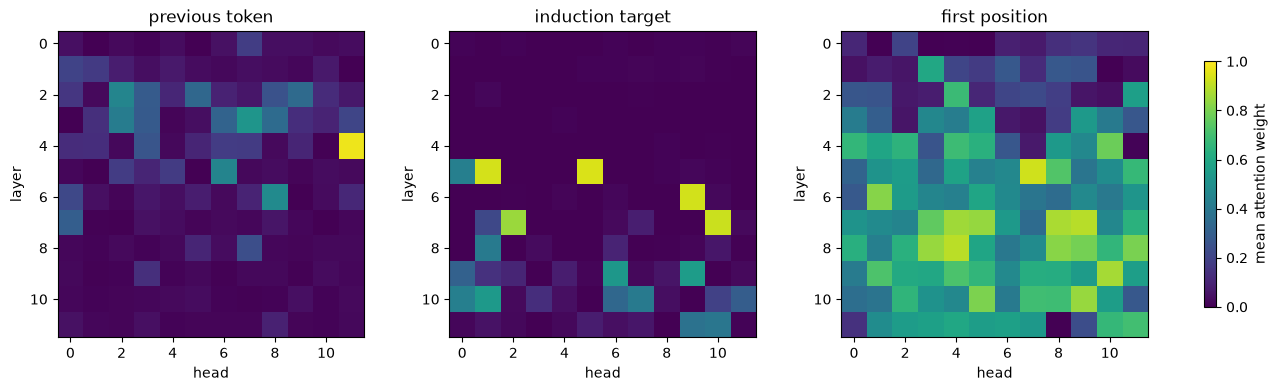

mean first-position score over all 144 heads: 0.44
previous-token heads (layer, head, score): [(4, 11, 0.97), (3, 7, 0.52), (6, 8, 0.48)]
induction heads: [(5, 5, 0.94), (5, 1, 0.93), (6, 9, 0.93), (7, 10, 0.92), (7, 2, 0.85), (9, 9, 0.55)]
first-position heads: [(5, 7, 0.93), (8, 4, 0.9), (7, 9, 0.89), (7, 8, 0.87), (9, 10, 0.87)]


In [7]:
T = att.shape[-1]
q2 = torch.arange(L + 1, 2 * L)                                            # positions in the second copy
prev_score = torch.stack([att[:, :, i, i - 1] for i in range(2, T)], -1).mean(-1)   # weight on the previous token
induction_score = att[:, :, q2, q2 - L + 1].mean(-1)                      # weight on the token AFTER the earlier copy of this token
first_score = att[:, :, 1:, 0].mean(-1)                                    # weight on the first position
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), constrained_layout=True)
for ax, (name, m) in zip(axes, [("previous token", prev_score), ("induction target", induction_score), ("first position", first_score)]):
    im = ax.imshow(m, cmap="viridis", vmin=0, vmax=1); ax.set(title=name, xlabel="head", ylabel="layer"); ax.set_xticks(range(0, 12, 2)); ax.set_yticks(range(0, 12, 2))
fig.colorbar(im, ax=axes, label="mean attention weight", shrink=0.8); plt.show()
def top(m, k): return [(int(i) // 12, int(i) % 12, round(float(m.flatten()[i]), 2)) for i in m.flatten().topk(k).indices]
print("mean first-position score over all 144 heads:", round(float(first_score.mean()), 2)); print("previous-token heads (layer, head, score):", top(prev_score, 3)); print("induction heads:", top(induction_score, 6)); print("first-position heads:", top(first_score, 5))

Each map shows one score per head, layers from the top. The previous-token pattern has one clear head: layer 4, head 11, with an average weight of 0.97 on the token before. The induction pattern has five heads at 0.85 or more: 5.5 (0.94), 5.1 (0.93), 6.9 (0.93), 7.10 (0.92) and 7.2 (0.85), then a weaker one, 9.9 (0.55). The first-position map is mostly green. The average over all 144 heads is 0.44, and five heads are at 0.87 or more, the highest being 5.7 (0.93).

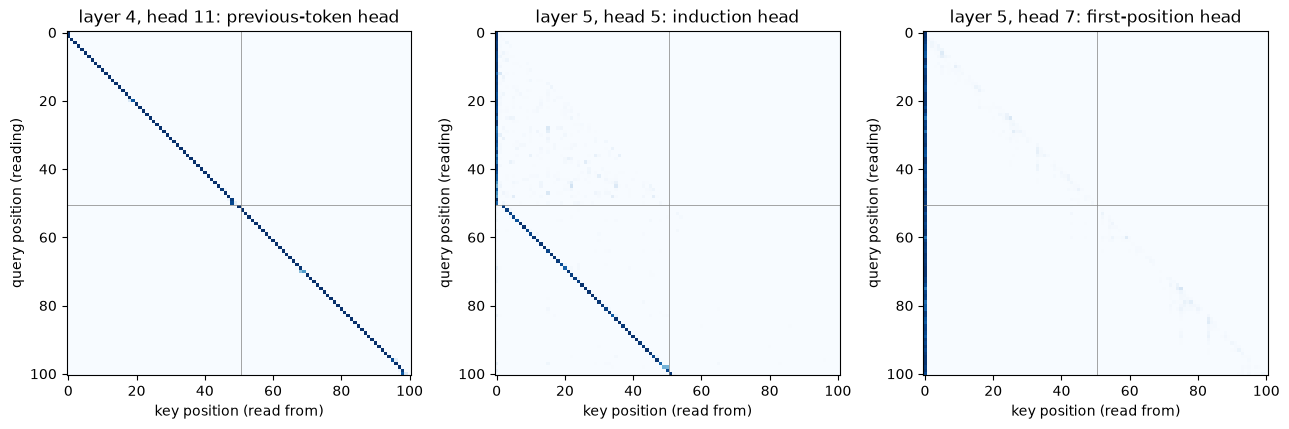

In [8]:
heads_to_show = [(4, 11, "previous-token head"), (5, 5, "induction head"), (5, 7, "first-position head")]
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, (l, h, name) in zip(axes, heads_to_show):
    ax.imshow(att[l, h], cmap="Blues", vmin=0, vmax=1); ax.set(title=f"layer {l}, head {h}: {name}", xlabel="key position (read from)", ylabel="query position (reading)")
    ax.axvline(L + 0.5, color="grey", lw=0.5); ax.axhline(L + 0.5, color="grey", lw=0.5)
plt.tight_layout(); plt.show()

The three heads in full, on the 101-token sequence (the grey lines mark where the second copy starts). Head 4.11 attends to the token just before, a single stripe next to the diagonal. Head 5.5 draws a diagonal stripe 49 positions to the left of the main diagonal in the second copy: each token reads the token that followed its earlier occurrence. In the first copy it has nothing to copy, and its weight goes to the first position. Head 5.7 reads the first position from almost every token, a vertical stripe at the left edge.

The layers fit the way an induction head is thought to work. A previous-token head in layer 4 can write into each token a note of which token came before it. An induction head in a later layer then looks for the token whose note matches the current token, which is the position just after the earlier copy. We have not tested that link here.

## 4. Does a clear pattern mean the head matters?

A head with a clean pattern looks like an explanation. The test is to switch heads off. We zero the output of chosen heads and measure the bits per token on the second copy again.

> **Pause:** if you remove the five heads with the strongest induction pattern, how many bits per token does the second copy cost? Compare: 0.65 with nothing removed, and 15.6 for pure guessing.

In [9]:
top_induction = [(l, h) for l, h, _ in top(induction_score, 5)]
top_first = [(l, h) for l, h, _ in top(first_score, 5)]
def second_copy_bits(heads): return float(ablate_heads(rep, heads)[L:].mean())
rng = np.random.default_rng(0)
others = [(l, h) for l in range(12) for h in range(12) if (l, h) not in top_induction]
random_sets = [second_copy_bits([others[i] for i in rng.choice(len(others), 5, replace=False)]) for _ in range(20)]
display(pd.DataFrame({"heads removed": ["none", "5 strongest induction heads", "5 strongest first-position heads", "5 random other heads (mean of 20 draws)", "5 random other heads (worst of 20 draws)"],
                      "bits per token, second copy": [float(bits[L:].mean()), second_copy_bits(top_induction), second_copy_bits(top_first), np.mean(random_sets), np.max(random_sets)]}).round(2))

,heads removed,"bits per token, second copy"
0,none,0.65
1,5 strongest induction heads,7.62
2,5 strongest first-position heads,0.67
3,5 random other heads (mean of 20 draws),0.76
4,5 random other heads (worst of 20 draws),1.08


Removing the five strongest induction heads raises the cost of the second copy from 0.65 to 7.62 bits per token. Removing five random other heads costs 0.76 bits on average, and 1.08 in the worst of 20 draws. So the heads that show the pattern are needed for the copying, and the effect is far larger than chance.

The five strongest first-position heads put 0.87 to 0.93 of their attention on one token, and removing them changes nothing (0.67 bits against 0.65). Heavy attention to a position does not mean the head's output is used.

The table below repeats the experiment on five other random sequences: the second copy costs between 0.58 and 0.91 bits, and removing the five induction heads raises it to between 5.4 and 11.1 bits. The effect holds in every case, with a size that depends on the sequence.

Now remove the heads one at a time.

In [10]:
rows = []
for seed in range(1, 6):
    s_ = torch.randint(1000, 40000, (L,), generator=torch.Generator().manual_seed(seed)); r_ = [tok.eos_token_id] + s_.tolist() * 2
    rows.append({"random sequence": seed, "first copy": float(bits_per_position(r_)[:L].mean()), "second copy": float(bits_per_position(r_)[L:].mean()), "second copy, 5 induction heads removed": float(ablate_heads(r_, top_induction)[L:].mean())})
display(pd.DataFrame(rows).set_index("random sequence").round(2))

,first copy,second copy,"second copy, 5 induction heads removed"
random sequence,,,
1,18.78,0.62,5.38
2,19.25,0.75,8.49
3,18.40,0.70,8.87
4,18.94,0.58,11.14
5,18.89,0.91,9.50


removing one induction head alone, extra bits per token: {'5.5': 0.0, '5.1': 0.43, '6.9': -0.0, '7.10': -0.05, '7.2': 0.05}
removing first-position head 5.7 alone: 0.019  (it puts 0.93 of its attention on the first token)


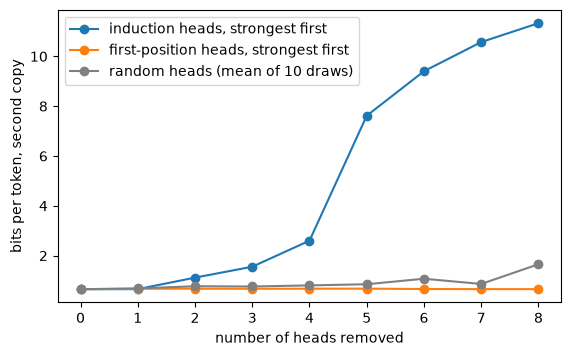

{'induction heads, strongest first': [0.65, 0.65, 1.12, 1.55, 2.6, 7.62, 9.4, 10.57, 11.33], 'first-position heads, strongest first': [0.65, 0.67, 0.67, 0.67, 0.67, 0.67, 0.66, 0.65, 0.65]}
random heads: [0.65, 0.68, 0.77, 0.76, 0.8, 0.85, 1.07, 0.86, 1.65]


In [11]:
effect = lambda heads: float(second_copy_bits(heads) - bits[L:].mean())
print("removing one induction head alone, extra bits per token:", {f"{l}.{h}": round(effect([(l, h)]), 2) for l, h in top_induction})
print("removing first-position head 5.7 alone:", round(effect([(5, 7)]), 3), " (it puts", round(float(first_score[5, 7]), 2), "of its attention on the first token)")
ks = range(0, 9)
orders = {"induction heads, strongest first": [(l, h) for l, h, _ in top(induction_score, 8)], "first-position heads, strongest first": [(l, h) for l, h, _ in top(first_score, 8)]}
curves = {name: [second_copy_bits(order[:k]) if k else bits[L:].mean() for k in ks] for name, order in orders.items()}
rng = np.random.default_rng(1)
draws = [[second_copy_bits([others[i] for i in rng.permutation(len(others))[:k]]) if k else bits[L:].mean() for k in ks] for _ in range(10)]
plt.figure(figsize=(6.5, 3.8))
for name, c in curves.items(): plt.plot(ks, c, marker="o", label=name)
plt.plot(ks, np.mean(draws, 0), marker="o", color="grey", label="random heads (mean of 10 draws)")
plt.xlabel("number of heads removed"); plt.ylabel("bits per token, second copy"); plt.legend(); plt.show()
print({name: [round(float(v), 2) for v in c] for name, c in curves.items()}); print('random heads:', [round(float(v), 2) for v in np.mean(draws, 0)])

One at a time, removing an induction head costs almost nothing. Head 5.5, the one with the cleanest stripe, costs 0.00 bits. Head 5.1 costs 0.43, and 6.9, 7.10 and 7.2 cost 0.00, -0.05 and 0.05. Removing heads in order of induction score gives 0.65, 0.65, 1.12, 1.55, 2.60 bits for 0 to 4 heads removed, then 7.62 for five, and 11.33 for eight. The model has several heads doing the same job. It still copies when one is gone, and only fails when most of them are. Removing first-position heads stays at 0.65 to 0.67 bits all the way to eight heads, and random heads rise to 1.65 bits at eight.

This gives a measured version of the warning from basic Session 11 that attention weights are not an explanation. A clear attention pattern was a good guide to which heads to test. It did not tell us that head 5.5 matters, since the model works without it, and the first-position heads, which attend just as heavily, turned out not to be needed for this task. Each of these findings needed an intervention.

## What to take away

- Attention for one head is $\operatorname{softmax}(QK^\top/\sqrt{d_k}+\text{mask})\,V$. Writing it by hand reproduces GPT-2's layer to 1e-6.
- Dividing by $\sqrt{d_k}$ keeps the softmax from saturating: without it the largest weight is 0.83 at $d_k=64$ and the gradient shrinks as the head size grows.
- GPT-2 has heads with identifiable jobs. Head 4.11 reads the previous token, and heads in layers 5 to 7 copy from an earlier occurrence of the same token.
- A pattern in the attention weights tells you where to test. Ablation tells you whether the head is used, and whether others can take over.

---

# Going deeper

*The rest of this notebook is for reading after the session.*

## Why $\sqrt{d_k}$

If the components of $q$ and $k$ are independent with mean 0 and variance 1, then $q\cdot k=\sum_{i=1}^{d_k}q_ik_i$ is a sum of $d_k$ terms, each with mean 0 and variance 1, so it has variance $d_k$ and standard deviation $\sqrt{d_k}$. Dividing by $\sqrt{d_k}$ gives scores with variance 1 at any head size.

The softmax Jacobian for weights $p$ is $\operatorname{diag}(p)-pp^\top$. When $p$ is nearly one-hot, this matrix is nearly zero, which is why saturated heads learn slowly.

## One matrix, many heads

GPT-2 stores the queries, keys and values for all heads in one $768\times2304$ matrix `c_attn`, because one large matrix multiplication is faster than 36 small ones. Our cell splits the product into three blocks and then reshapes each into (heads, tokens, 64). The outputs of the 12 heads are joined back to 768 numbers and multiplied by the output matrix `c_proj`. That matrix is where `ablate_heads` intervenes: blanking columns $64h$ to $64h+63$ of its input removes head $h$.

## The induction circuit

Induction is usually described as two heads working together. A previous-token head in an early layer copies each token's identity into the next position, so that position $j$ carries a note "my predecessor was $A$". An induction head in a later layer forms a query from the current token $A$ and matches it against these notes, so it attends to position $j$, the token that followed $A$ last time. Its value pathway then raises the probability of that token. Our results fit this picture (head 4.11 in layer 4, induction heads in layers 5 to 7) but do not prove it. A proof would patch the previous-token head's output and see whether the induction heads' attention changes.

## Attention sinks

Many heads put a large weight on the first token, even when it carries no information. A softmax must distribute a total weight of 1, so a head with nothing relevant to read needs somewhere to send the weight. The first position, which every token can see under the causal mask, becomes that place. The values stored there are small, so reading it changes little. Our ablation agrees: the five heads with the most first-position attention can be removed at no cost.

## Limits of this ablation

- Zeroing a head's output moves the next layer's input to a value it never saw in training. Replacing the output with its average over many inputs (mean ablation) is gentler, and the effect sizes can change.
- We test one task, copying random tokens. A head that is unneeded here may matter for other text.
- Removing several heads together, as we did, can be misleading when the heads depend on each other. The five induction heads may not all be needed to the same degree.
- Models learn redundant circuits, so a single-head removal can understate what the head does, as head 5.5 shows.